# Lab 1 - A Simple Fingerprint Biometric System
 
**Name:** aumamh alisary
 
**Student ID:** 2421304


In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import fp_tools as fp          # our helper file
 
DATA = "fingerprint_data"
files = sorted(os.listdir(DATA))
print("Number of images:", len(files))
print("First five:", files[:5])


Number of images: 42
First five: ['P01_1.png', 'P01_2.png', 'P01_3.png', 'P01_4.png', 'P02_1.png']


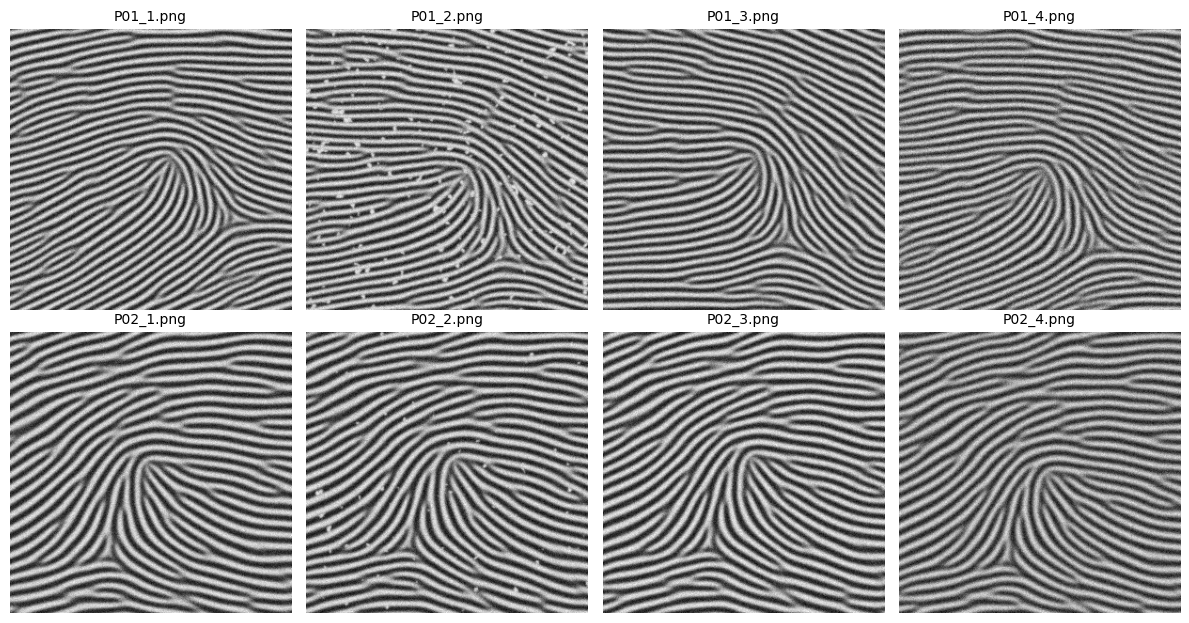

In [2]:
paths = [f"{DATA}/P01_{k}.png" for k in range(1, 5)] + [f"{DATA}/P02_{k}.png" for k in range(1, 5)]
fp.show_images(paths, cols=4)



In the top row (scans of the same finger from P01), two clear differences between the impressions are:
1. **Position and Shift:** The finger is placed at slightly different horizontal and vertical locations across the scans.
2. **Rotation and Angle:** The finger is tilted/rotated slightly differently in each image. 
*(Differences in brightness and ridge thickness due to contact pressure are also visible).*

Looking at the bottom row (P02), it is clearly visible that P02 has a different ridge pattern from P01. While P01 exhibits a specific core flow (loop/whorl), P02 shows distinct global ridge orientation and curvature, confirming that they belong to two completely different individuals.

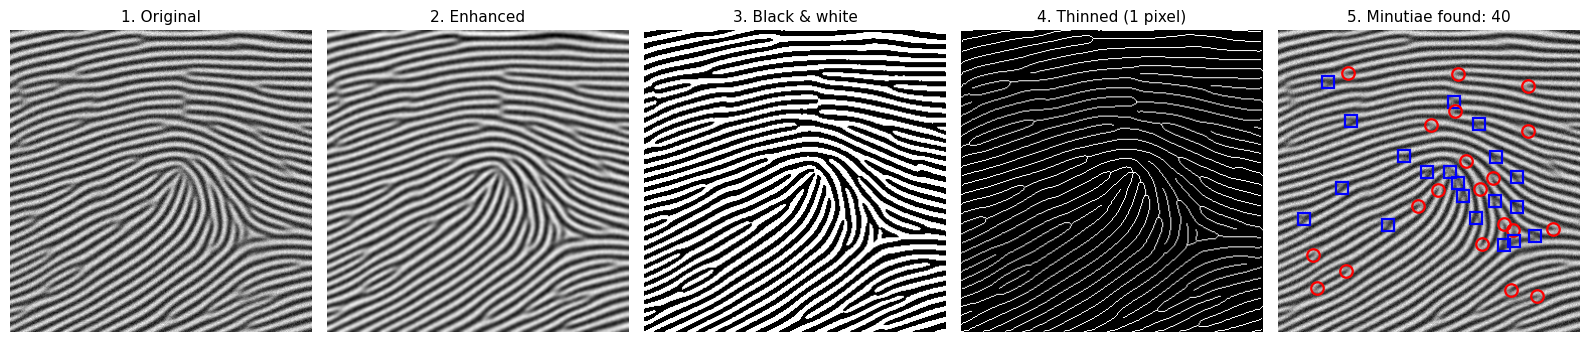

In [3]:
minutiae = fp.show_pipeline(f"{DATA}/P01_1.png")

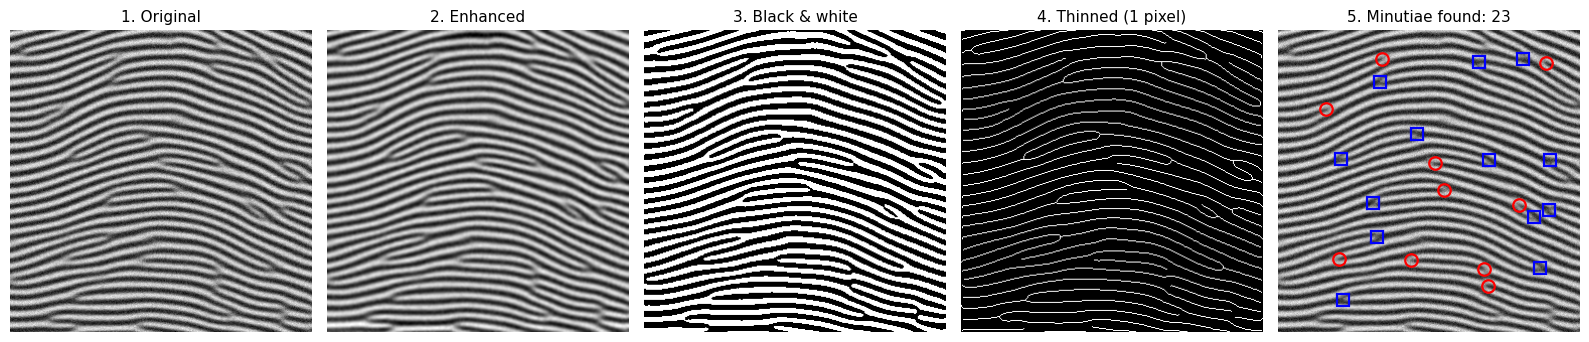

In [4]:
minutiae = fp.show_pipeline(f"{DATA}/P05_1.png")

in P05_1.png the number of detected minutiae is significantly smaller then P01_1.png

In [5]:
print("Table shape (rows, columns):", minutiae.shape)
print("First three minutiae [x, y, angle, type]:")
print(np.round(minutiae[:3], 2))
print("Ridge endings   :", int((minutiae[:, 3] == 0).sum()))
print("Bifurcations    :", int((minutiae[:, 3] == 1).sum()))


Table shape (rows, columns): (23, 4)
First three minutiae [x, y, angle, type]:
[[1.03e+02 2.80e+01 2.81e+00 0.00e+00]
 [2.43e+02 2.80e+01 3.70e-01 1.00e+00]
 [1.99e+02 3.10e+01 1.90e-01 1.00e+00]]
Ridge endings   : 10
Bifurcations    : 13


In [6]:
database = {}
for person in range(1, 11):
    person_id = f"P{person:02d}"
    database[person_id] = fp.extract_template(f"{DATA}/{person_id}_1.png")
 
for person_id, template in database.items():
    print(person_id, "->", len(template), "minutiae")


P01 -> 40 minutiae
P02 -> 36 minutiae
P03 -> 50 minutiae
P04 -> 41 minutiae
P05 -> 23 minutiae
P06 -> 47 minutiae
P07 -> 44 minutiae
P08 -> 58 minutiae
P09 -> 42 minutiae
P10 -> 53 minutiae


In [7]:
to_save = {pid: t.tolist() for pid, t in database.items()}
with open("templates.json", "w") as f:
    json.dump(to_save, f)
print("Saved", len(to_save), "templates to templates.json")


Saved 10 templates to templates.json


In [8]:
probe_genuine = fp.extract_template(f"{DATA}/P01_2.png")

probe_impostor = fp.extract_template(f"{DATA}/P02_2.png")
 
score_g, pairs_g = fp.match(database["P01"], probe_genuine)
score_i, pairs_i = fp.match(database["P01"], probe_impostor)
print("Genuine  (P01 vs P01): paired =", len(pairs_g), " score = %.1f" % score_g)
print("Impostor (P01 vs P02): paired =", len(pairs_i), " score = %.1f" % score_i)


Genuine  (P01 vs P01): paired = 29  score = 25.3
Impostor (P01 vs P02): paired = 8  score = 3.8


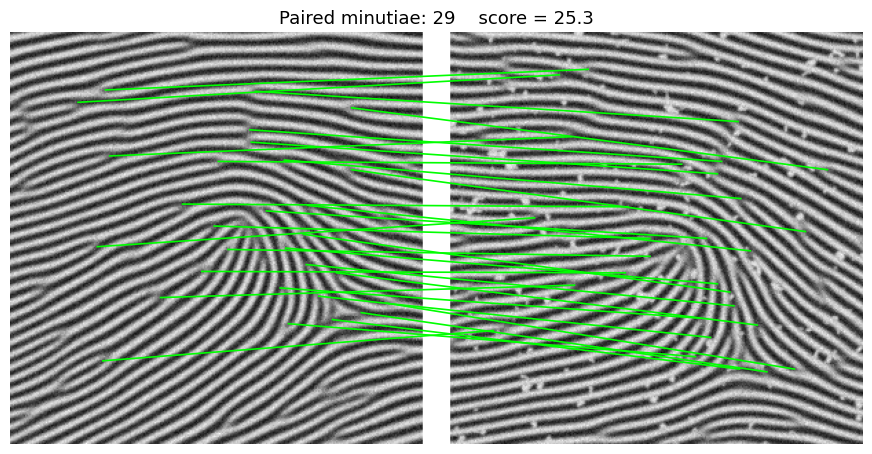

In [9]:
fp.show_match(f"{DATA}/P01_1.png", f"{DATA}/P01_2.png", database["P01"], probe_genuine, pairs_g, score_g)

The genuine comparison achieved a much higher match score (25.3) than the impostor comparison (3.8) because scans from the same finger share significantly more paired minutiae. If the threshold were set to 12, the genuine score (25.3) would be accepted since it is above 12, while the impostor score (3.8) would be rejected because it falls below the threshold.

In [10]:
THRESHOLD = 12
 
def verify(claimed_id, probe_path, threshold=THRESHOLD):
    probe = fp.extract_template(probe_path)
    score, pairs = fp.match(database[claimed_id], probe)
    decision = "ACCEPT" if score >= threshold else "REJECT"
    return decision, round(score, 1)
 
print("Real P03   :", verify("P03", f"{DATA}/P03_2.png"))
print("Real P03   :", verify("P03", f"{DATA}/P03_4.png"))
print("Impostor   :", verify("P03", f"{DATA}/P07_2.png"))
print("Impostor   :", verify("P03", f"{DATA}/S01_1.png"))



Real P03   : ('ACCEPT', 45.5)
Real P03   : ('ACCEPT', 79.0)
Impostor   : ('REJECT', 2.5)
Impostor   : ('REJECT', 6.1)


When setting THRESHOLD = 50, the first real scan of P03 (which had a match score of 45.5) is now wrongly rejected (False Non-Match / False Rejection). This happens because the threshold is set too strictly high (50). Even though this scan belongs to the genuine user (P03), natural physical scan variations—such as rotation, position shift, or slight pressure differences—caused its match score to drop to 45.5, which is lower than the required threshold of 50\. Meanwhile, the other scan scored 79.0 and was accepted. This clearly demonstrates how raising the threshold too high increases genuine user rejection (FNMR).

In [11]:
def identify(probe_path, threshold=THRESHOLD):
    probe = fp.extract_template(probe_path)
    best_id, best_score = None, 0
    for person_id, template in database.items():
        score, _ = fp.match(template, probe)
        if score > best_score:
            best_id, best_score = person_id, score
    if best_score >= threshold:
        return best_id, round(best_score, 1)
    return "UNKNOWN", round(best_score, 1)
 
print(identify(f"{DATA}/P05_3.png"))
print(identify(f"{DATA}/P08_2.png"))
print(identify(f"{DATA}/S02_1.png"))


('P05', 62.8)
('P08', 47.1)
('UNKNOWN', 7.8)


In [12]:
genuine_scores, impostor_scores = [], []
for person in range(1, 11):
    pid = f"P{person:02d}"
    for k in (2, 3, 4):
        probe = fp.extract_template(f"{DATA}/{pid}_{k}.png")
        for other_id, template in database.items():
            score, _ = fp.match(template, probe)
            if other_id == pid:
                genuine_scores.append(score)
            else:
                impostor_scores.append(score)
 
genuine = np.array(genuine_scores)
impostor = np.array(impostor_scores)
print("Genuine comparisons :", len(genuine), "  average score = %.1f" % genuine.mean())
print("Impostor comparisons:", len(impostor), "  average score = %.1f" % impostor.mean())


Genuine comparisons : 30   average score = 60.4
Impostor comparisons: 270   average score = 3.4


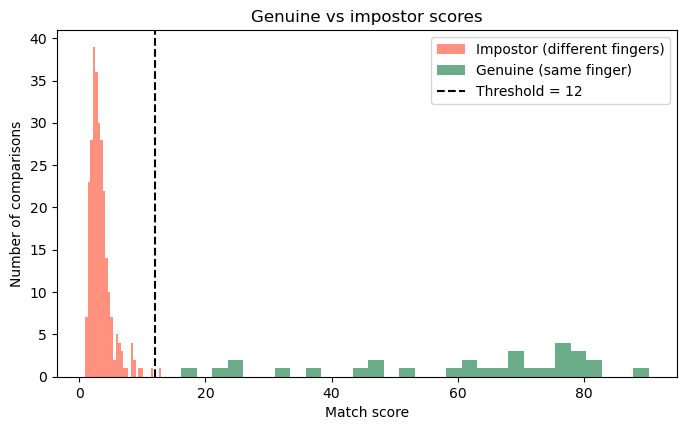

In [13]:
plt.figure(figsize=(8, 4.5))
plt.hist(impostor, bins=30, alpha=0.7, color="tomato", label="Impostor (different fingers)")
plt.hist(genuine, bins=30, alpha=0.7, color="seagreen", label="Genuine (same finger)")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"Threshold = {THRESHOLD}")
plt.xlabel("Match score")
plt.ylabel("Number of comparisons")
plt.title("Genuine vs impostor scores")
plt.legend()
plt.savefig("score_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
print("Threshold   FNMR (%)   FMR (%)")
for t in [5, 8, 10, 12, 15, 20, 30, 40]:
    fnmr = 100 * np.mean(genuine < t)
    fmr = 100 * np.mean(impostor >= t)
    print(f"{t:9d}   {fnmr:8.1f}   {fmr:7.2f}")


Threshold   FNMR (%)   FMR (%)
        5        0.0     11.85
        8        0.0      3.70
       10        0.0      1.11
       12        0.0      0.37
       15        0.0      0.00
       20        3.3      0.00
       30       13.3      0.00
       40       20.0      0.00


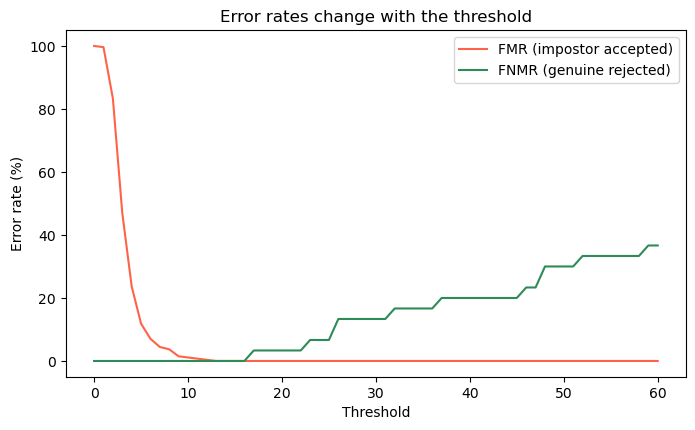

In [15]:
thresholds = np.arange(0, 61)
fmr_curve = [100 * np.mean(impostor >= t) for t in thresholds]
fnmr_curve = [100 * np.mean(genuine < t) for t in thresholds]
 
plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, fmr_curve, color="tomato", label="FMR (impostor accepted)")
plt.plot(thresholds, fnmr_curve, color="seagreen", label="FNMR (genuine rejected)")
plt.xlabel("Threshold")
plt.ylabel("Error rate (%)")
plt.title("Error rates change with the threshold")
plt.legend()
plt.savefig("error_curve.png", dpi=150, bbox_inches="tight")
plt.show()


## Part I. Choose a threshold
 
**Phone unlock (convenience):** threshold = 8 because FNMR is 0.0%
This will make it always easy for a person to access their phone.
 
**Bank vault (security):** threshold = 20 because FMR is 0.0%
so, no untrusted person will be able to access the bank.


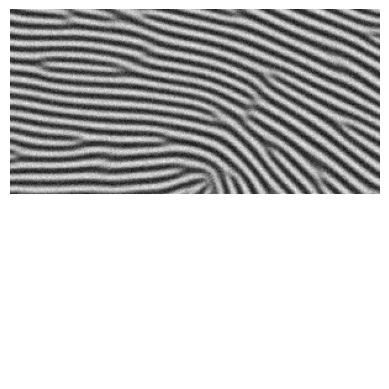

Half-covered genuine print: paired = 10  score = 10.9


In [16]:
img = fp.load_image(f"{DATA}/P01_3.png")
partial = fp.cover(img, 0.5)
plt.imshow(partial, cmap="gray"); plt.axis("off"); plt.show()
 
probe = fp.extract_template(partial)
score, pairs = fp.match(database["P01"], probe)
print("Half-covered genuine print: paired =", len(pairs), " score = %.1f" % score)


When testing different covered fractions, P01 stops being rejected at a fraction of about \*\*0.4\*\* (or lower): 
- At 0.4: score = 27.3 (accepted, since 27.3 >= 12)
- At 0.3: score = 33.6 (accepted)
- At 0.2: score = 42.2 (accepted) As the covered area decreases from 0.5 (where score was 10.9 and rejected) down to 0.4, enough minutiae remain visible to push the score well above the threshold of 12\. To handle partial prints in real life, the system could prompt the user with a message asking them to lift their finger and press again firmly in the center of the sensor (or capture multiple impressions from different angles during enrolment)